# 3. Aggregation and reports

A reduction turns matched values into one value per target. Which reductions make sense depends on
the **kind** of value:

| kind | example | moves by | typical reductions |
|---|---|---|---|
| extensive | population, crashes | splitting the total | `sum`, `density`, `count` |
| intensive | median income, temperature | averaging | `weighted_mean`, `mean`, `min`, `max` |
| categorical | land use, severity | counting categories | `shares`, `majority` |

urbanweave checks the kinds you declare, keeps missing values missing, keeps integer sums exact, and
reports where totals went.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly

In [2]:
districts = td.districts()
tracts = td.tracts()
crashes = td.crashes()
tracts.drop(columns="geometry").head()

,tract_id,population,median_income
0,T00,1524,93100.0
1,T01,2047,61200.0
2,T02,3502,NaN
3,T03,3551,56300.0
4,T04,2507,70300.0


## Extensive and intensive values together

Population is extensive: a tract split 70/30 between two districts gives 70% of its people to the
first. Median income is intensive: it is not split but averaged, weighted by the overlapping area
(`weighted_mean`). One match serves both.

In [3]:
m = uw.match(tracts, districts, "area_overlap", source_id="tract_id", target_id="district_id")
out = uw.aggregate(m, None, [
    uw.sum("population", as_="population"),
    uw.density("population", as_="people_per_km2"),
    uw.weighted_mean("median_income", as_="income"),
], value_kinds={"population": "extensive", "median_income": "intensive"})
out[["name", "population", "people_per_km2", "income"]].round(0)

,name,population,people_per_km2,income
0,Northgate,6840.0,5506.0,77970.0
1,Old Town,17520.0,17305.0,59706.0
2,Eastfield,10244.0,9011.0,77233.0
3,Mill District,9623.0,7135.0,76947.0
4,Riverside,10564.0,8386.0,75348.0


In [4]:
print("tracts:", tracts["population"].sum(), " districts:", round(out["population"].sum(), 6))
show(uw.report_of(out)["aggregate"][0]["extensive"])   # the tiny "unallocated" is floating-point rounding

tracts: 54791  districts: 54791.0
{
 "valid_input": 54791.0,
 "matched_input": 54791.0,
 "unmatched_input": 0.0,
 "allocated": 54790.9999999992,
 "unallocated": 8.003553375601768e-10
}


Two tracts have no reported income (the park, where nobody lives, and one suppressed for
privacy). They are **left out of the average**, not counted as zero income, and the report counts
them.

In [5]:
show(uw.report_of(out)["aggregate"][2]["values"])

{
 "missing": 3,
 "not_numeric": 0,
 "not_finite": 0,
 "valid": 30
}


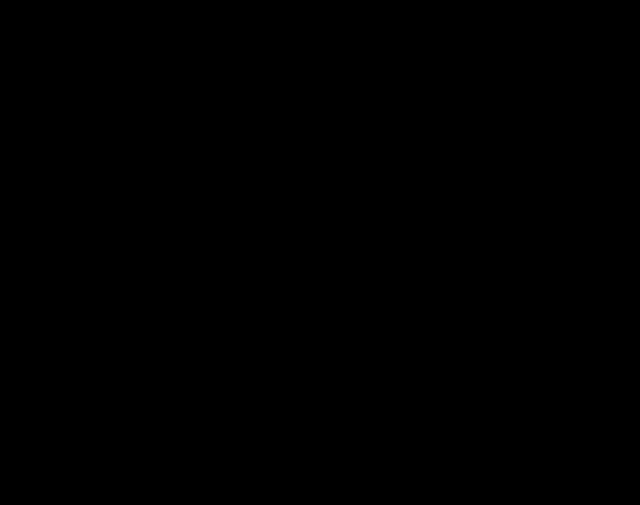

In [6]:
(Map("Median household income, area-weighted by district")
 .fill(out, "income", legend="median income ($)", tooltip=["name"])
 .outline(tracts, width=0.6)
 .outline(districts, label="name", width=2))

## Declared kinds are checked

Summing an intensive value is almost always a mistake (adding median incomes gives a meaningless
number). With the kind declared, urbanweave refuses and says why.

In [7]:
try:
    uw.aggregate(m, None, [uw.sum("median_income")], value_kinds={"median_income": "intensive"})
except uw.UrbanweaveError as err:
    print(type(err).__name__, "—", err)

UnsupportedError — sum does not suit intensive values ('median_income'); it takes extensive.


## Zero, or missing?

Some answers are genuinely zero, others are undefined. On a fine grid many cells have no crash:

- the **number of crashes** in such a cell is 0, a measured zero. `fill_empty=0` says so; it is
  allowed only for `count`, `weighted_count` and `sum`;
- the **injuries per crash** in such a cell is undefined, so it stays missing, and the map hatches
  it rather than painting it as zero.

`where` filters the matched rows: a cell with crashes but none serious counts 0 serious crashes.

In [8]:
cells = uw.targets.h3_cells(crashes.to_crs(4326), 10)
severe = {"column": "severity", "op": "==", "value": "serious"}
per_cell = uw.aggregate(uw.match(crashes, cells, "contain"), None, [
    uw.count(as_="crashes", fill_empty=0),
    uw.count(as_="serious", where=severe, fill_empty=0),
    uw.mean("persons_injured", as_="injured_per_crash"),
])
print(len(per_cell), "cells;", int((per_cell["crashes"] == 0).sum()), "with no crash;",
      int(per_cell["injured_per_crash"].isna().sum()), "with injuries per crash missing")
per_cell[["target_id", "crashes", "serious", "injured_per_crash"]].head()

380 cells; 166 with no crash; 166 with injuries per crash missing


,target_id,crashes,serious,injured_per_crash
0,8a2a12a98007fff,0,0,<NA>
1,8a2a12a9800ffff,0,0,<NA>
2,8a2a12a98017fff,0,0,<NA>
3,8a2a12a9801ffff,2,0,0.5
4,8a2a12a98027fff,1,0,1.0


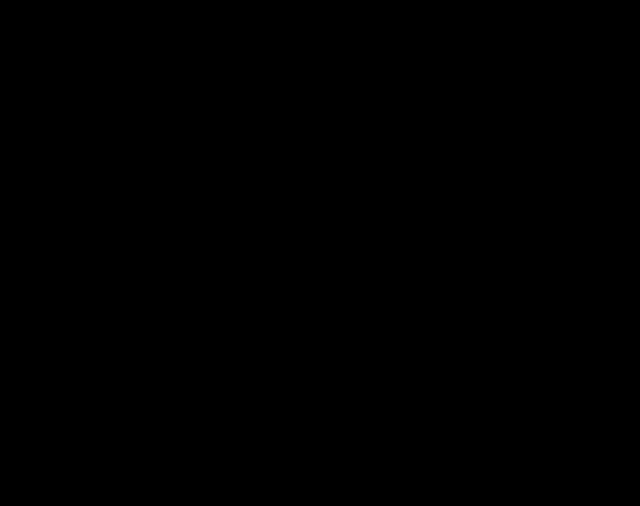

In [9]:
(Map("Crashes per cell: zero where there were none")
 .fill(per_cell, "crashes", legend="crashes", classes=5)
 .outline(districts, label="name", width=2))

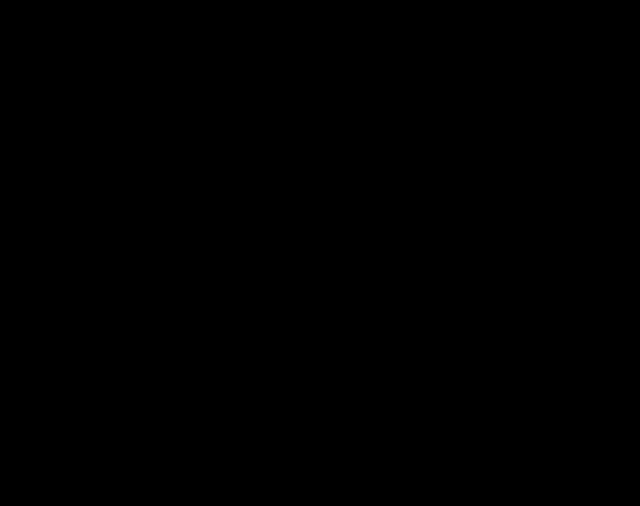

In [10]:
(Map("Injuries per crash: missing where there was no crash")
 .fill(per_cell, "injured_per_crash", legend="persons injured per crash", classes=5)
 .outline(districts, label="name", width=2))

## Categories: shares and majority

`shares` gives the fraction of each category per target, and `majority` the most frequent one (ties
go to the smallest category, so results do not depend on row order).

In [11]:
m = uw.match(crashes, districts, "contain", target_id="district_id")
mix = uw.aggregate(m, None, [uw.shares("severity", as_="share"), uw.majority("severity", as_="usual")])
mix.drop(columns="geometry").round(3)

,district_id,name,share_injury,share_property,share_serious,usual
0,NG,Northgate,0.254,0.644,0.102,property
1,OT,Old Town,0.322,0.607,0.07,property
2,EF,Eastfield,0.293,0.598,0.109,property
3,MD,Mill District,0.198,0.679,0.123,property
4,RS,Riverside,0.232,0.726,0.042,property


## Partial coverage is reported, not hidden

A planning study area that reaches past the town edge only receives the people of the tracts it
covers. The report separates what was allocated from what was not, so a total that looks low can be
explained.

In [12]:
from shapely.geometry import box
study = td.gpd.GeoDataFrame({"target_id": ["corridor"]},
                            geometry=[box(td.X0 + 600, td.Y0 - 400, td.X0 + 2100, td.Y0 + 400)], crs=td.CRS)
cov = uw.aggregate(uw.match(tracts, study, "area_overlap"), None, [uw.sum("population", as_="population")])
print("corridor population:", round(cov["population"].iloc[0]))
show(uw.report_of(cov)["aggregate"][0]["extensive"])

corridor population: 6442
{
 "valid_input": 54791.0,
 "matched_input": 21218.0,
 "unmatched_input": 33573.0,
 "allocated": 6441.82314650784,
 "unallocated": 48349.17685349216
}


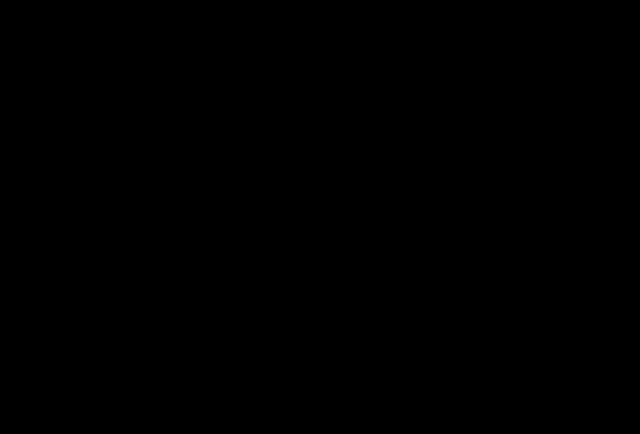

In [13]:
(Map("A study corridor that extends past the town")
 .fill(tracts, "population", legend="population per tract")
 .outline(study, label="target_id", width=2.5))

## Integer totals stay exact

Counts and other integers are summed exactly, as integers, when the weights are whole (here
`contain` gives each crash wholly to one tract). A sum that would overflow 64-bit integers is
reported rather than wrapped.

In [14]:
per_tract_int = uw.aggregate(uw.match(crashes, tracts, "contain", target_id="tract_id"), None,
                             [uw.sum("persons_injured", as_="injured", fill_empty=0)])
per_tract_int["injured"].dtype, int(per_tract_int["injured"].sum()), int(crashes["persons_injured"].sum())

(Int64Dtype(), 272, 272)

**Next:** [4. H3 as a bridge](04_h3_as_a_bridge.ipynb).